<a href="https://colab.research.google.com/github/asciosh/lumen-x/blob/main/notebooks/01_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

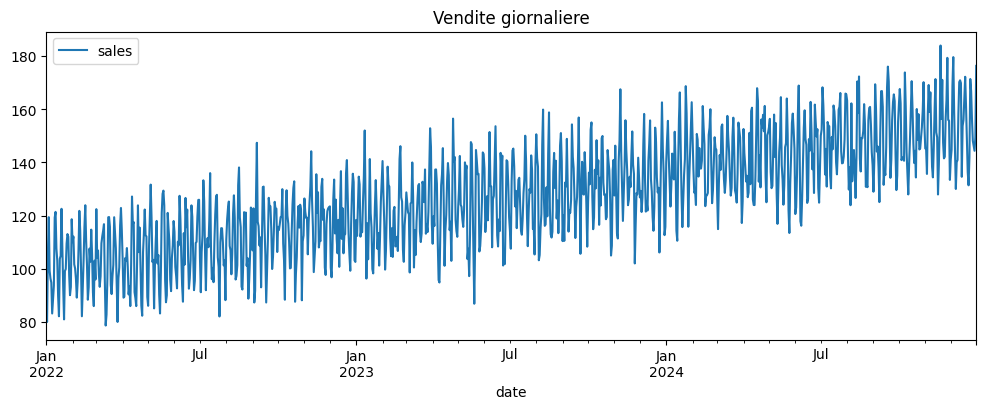

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Dati sintetici: trend + stagionalità settimanale + rumore
# (sostituisci con il dataset Kaggle quando vuoi)
rng = np.random.default_rng(42)
dates = pd.date_range("2022-01-01", "2024-12-31", freq="D")
t = np.arange(len(dates))
weekly = 15 * np.sin(2 * np.pi * dates.dayofweek / 7)
sales = 100 + 0.05 * t + weekly + rng.normal(0, 8, len(dates))
df = pd.DataFrame({"date": dates, "sales": sales}).set_index("date")
df = df.asfreq("D")

df.plot(figsize=(12, 4), title="Vendite giornaliere")
plt.show()

In [7]:
def mape(y, yhat):
    return np.mean(np.abs((y - yhat) / y)) * 100

def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))

def mase(y, yhat, y_train, m=7):
    # errore scalato sul naive stagionale in-sample
    scale = np.mean(np.abs(y_train[m:] - y_train[:-m]))
    return np.mean(np.abs(y - yhat)) / scale

In [8]:
HORIZON = 28
SEASON = 7

def naive_seasonal(train, h):
    # ripete l'ultima settimana osservata
    last = train.values[-SEASON:]
    return np.tile(last, h // SEASON + 1)[:h]

def ets(train, h):
    model = ExponentialSmoothing(
        train, trend="add", seasonal="add", seasonal_periods=SEASON
    ).fit()
    return model.forecast(h).values

In [9]:
def backtest(series, model_fn, initial=365, horizon=HORIZON, step=28):
    rows = []
    for end in range(initial, len(series) - horizon + 1, step):
        train = series.iloc[:end]
        test = series.iloc[end:end + horizon]
        pred = model_fn(train, horizon)
        rows.append({
            "cutoff": series.index[end - 1],
            "MAPE": mape(test.values, pred),
            "RMSE": rmse(test.values, pred),
            "MASE": mase(test.values, pred, train.values),
        })
    return pd.DataFrame(rows)

results = {
    "naive stagionale": backtest(df["sales"], naive_seasonal),
    "ETS": backtest(df["sales"], ets),
}

summary = pd.DataFrame({k: v[["MAPE", "RMSE", "MASE"]].mean() for k, v in results.items()}).T
summary

,MAPE,RMSE,MASE
naive stagionale,6.633001,11.163402,1.036523
ETS,4.808795,8.059588,0.739628


## Risultati del backtesting

Backtesting a finestra espandibile, orizzonte 28 giorni, su dati sintetici (trend + stagionalità settimanale + rumore).

| Modello | MAPE | RMSE | MASE |
|---|---|---|---|
| Naive stagionale | 6,63 | 11,16 | 1,04 |
| ETS | 4,81 | 8,06 | 0,74 |

L'ETS riduce l'errore di circa il 27% rispetto al baseline (MAPE 4,8% vs 6,6%). Il risultato è su dati sintetici e serve a validare la pipeline: il prossimo passo è un dataset reale (Store Sales di Kaggle) e l'aggiunta di LightGBM.

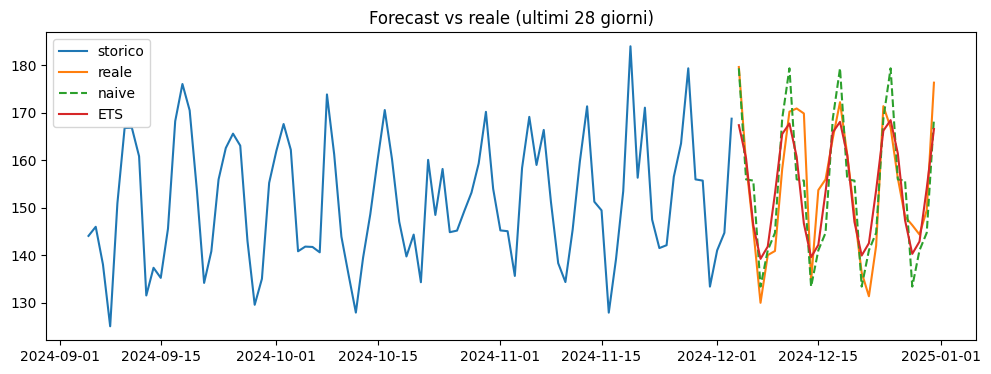

In [10]:
cut = len(df) - HORIZON
train, test = df["sales"].iloc[:cut], df["sales"].iloc[cut:]

plt.figure(figsize=(12, 4))
plt.plot(train.index[-90:], train.values[-90:], label="storico")
plt.plot(test.index, test.values, label="reale")
plt.plot(test.index, naive_seasonal(train, HORIZON), "--", label="naive")
plt.plot(test.index, ets(train, HORIZON), label="ETS")
plt.legend()
plt.title("Forecast vs reale (ultimi 28 giorni)")
plt.savefig("forecast.png", dpi=150, bbox_inches="tight")
plt.show()